In [58]:
import os
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print (device)


episodes = 100

N_runs    = 1
all_returns = []

cuda


In [59]:

from pathlib import Path
import numpy as np
import time
from IPython.display import display
import pandas as pd
import datetime
import pandas as pd
import matplotlib
#matplotlib.use("Agg")   # <<< CRITICAL for server (no display)
import math
import sys
import numpy as np
import random
import matplotlib.pyplot as plt
import itertools
from collections import defaultdict
import logging
import argparse
import gymnasium as gym
import numpy as np
import os
import glob
import gurobipy as gp
from concurrent.futures import ProcessPoolExecutor
from concurrent.futures import ProcessPoolExecutor, as_completed
from gymnasium import spaces
from matplotlib import figure
import matplotlib.pyplot as plt
%matplotlib inline
matplotlib.rcParams['figure.max_open_warning'] = 0
from IPython.display import display
from IPython.display import clear_output
clear_output(wait=True)
import torch.nn as nn
import torch.optim as optim
import numpy as np
import gurobipy as gp
import scipy.sparse as sp



def extract_sparse_model_matrices(model):
    """
    Extracts the entire .mps file into SciPy CSR sparse matrices ONCE at startup.
    """
    
    all_vars = model.getVars()
    all_constrs = model.getConstrs()
    
    num_vars = len(all_vars)
    num_constrs = len(all_constrs)
    
    # 1. Coordinate collection lists for efficient sparse building
    row_indices = []
    col_indices = []
    coefficients = []
    
    b_full = np.zeros(num_constrs)
    senses = np.zeros(num_constrs, dtype=object)
    
    # 2. Extract structural data via Gurobi's fast variable index mapping
    for c_idx, constr in enumerate(all_constrs):
        lhs_expr = model.getRow(constr)
        for i in range(lhs_expr.size()):
            v_idx = lhs_expr.getVar(i).index
            
            row_indices.append(c_idx)
            col_indices.append(v_idx)
            coefficients.append(lhs_expr.getCoeff(i))
        
        b_full[c_idx] = constr.RHS
        senses[c_idx] = constr.Sense

    # 3. Create the initial sparse matrix using the collected coordinates
    A_sparse = sp.coo_matrix((coefficients, (row_indices, col_indices)), 
                              shape=(num_constrs, num_vars)).tocsr()

    # 4. Compute DFP Scale Factors (Max value per row across coefficients AND RHS)
    # To get the max absolute coefficient per row in a CSR matrix safely and quickly:
    #max_coeff_per_row = np.zeros(num_constrs)
    row_scales_vector = np.zeros(num_constrs)
    for i in range(num_constrs):
        row_data = A_sparse.getrow(i).data
        row_data = np.append(row_data, b_full[i])  # Include RHS in max calculation
        #if row_data.size > 0:
        #    max_coeff_per_row[i] = np.max(np.abs(row_data))

        # 4. Apply the normalization denominator
        l1_norm = np.linalg.norm(row_data, ord=1)
        l2_norm = np.linalg.norm(row_data, ord=2)
        linf_norm = np.linalg.norm(row_data, ord=np.inf)
        lmax_norm = max(l1_norm, l2_norm, linf_norm)
        row_scales_vector[i] = l1_norm 

    row_scales_vector = np.array(row_scales_vector, dtype=float)
    row_scales_vector[row_scales_vector < 1e-9] = 1.0  # Protect against division by zero
    inv_multipliers = 1.0 / row_scales_vector
    
    # Create a sparse diagonal matrix out of the inverse multipliers
    D_scaling_matrix = sp.diags(inv_multipliers)
    
    # Matrix-Matrix multiplication scales rows simultaneously
    A_scaled = D_scaling_matrix @ A_sparse
    
    # Standard element-wise array multiplication for the RHS vector
    b_scaled = b_full * inv_multipliers
    # 6. Create boolean masks for fast vectorized filtering during training
    le_mask = (senses == '<')
    ge_mask = (senses == '>')
    eq_mask = (senses == '=')
    
    return A_scaled, b_scaled, le_mask, ge_mask, eq_mask






def load_model(prob):
    gmodel = gp.read(prob)
    gmodel.Params.OutputFlag = 0          # ✅ reads .mps natively, no conversion needed
    return gmodel





# ─────────────────────────────────────────
# (Solving the BIP by adding the bounds of the variables from vec so that we get the solution corresponding to each of the states)
# ─────────────────────────────────────────
def solve_bip_gurobi(gmodel, vec, relax):
    # Relaxation
    if relax == True:
        gmodel = gmodel.relax()
    # Apply bounds if provided
    var_list = gmodel.getVars()
    N = len(var_list)
    if vec is not None:
        if len(vec) != 2 * N:
            raise ValueError(f"vec must have length 2*N={2*N}, got {len(vec)}")
        for i, var in enumerate(var_list):
            var.LB = vec[i]          # lower bound
            var.UB = vec[i + N]      # upper bound
        gmodel.update()               # ✅ must call update() after changing bounds



    # Solve
    gmodel.optimize()

    # Status

    status_map = {
        gp.GRB.LOADED:          'LOADED',           # 1  - Model loaded, not yet solved
        gp.GRB.OPTIMAL:         'OPTIMAL',           # 2  - Optimal solution found
        gp.GRB.INFEASIBLE:      'INFEASIBLE',        # 3  - Model is infeasible
        gp.GRB.INF_OR_UNBD:     'INF_OR_UNBD',       # 4  - Infeasible or unbounded
        gp.GRB.UNBOUNDED:       'UNBOUNDED',         # 5  - Model is unbounded
        gp.GRB.CUTOFF:          'CUTOFF',            # 6  - Objective worse than cutoff
        gp.GRB.ITERATION_LIMIT: 'ITERATION_LIMIT',   # 7  - Iteration limit reached
        gp.GRB.NODE_LIMIT:      'NODE_LIMIT',        # 8  - Node limit reached (MIP)
        gp.GRB.TIME_LIMIT:      'TIME_LIMIT',        # 9  - Time limit reached
        gp.GRB.SOLUTION_LIMIT:  'SOLUTION_LIMIT',    # 10 - Solution limit reached
        gp.GRB.INTERRUPTED:     'INTERRUPTED',       # 11 - Solve interrupted by user
        gp.GRB.NUMERIC:         'NUMERIC',           # 12 - Numerical issues
        gp.GRB.SUBOPTIMAL:      'SUBOPTIMAL',        # 13 - Suboptimal solution available
        gp.GRB.INPROGRESS:      'INPROGRESS',        # 14 - Solve currently in progress
        gp.GRB.USER_OBJ_LIMIT:  'USER_OBJ_LIMIT',    # 15 - User objective limit reached
        gp.GRB.WORK_LIMIT:      'WORK_LIMIT',        # 16 - Work limit reached
        gp.GRB.MEM_LIMIT:       'MEM_LIMIT',         # 17 - Memory limit reached
    }

    # Safe lookup with fallback
    tc = status_map.get(gmodel.Status, f'UNKNOWN({gmodel.Status})')
    #print(f"Solver status: {tc}")

    SOLUTION_EXISTS = {'OPTIMAL', 'SUBOPTIMAL'}

    LIMIT_REACHED = {
        'TIME_LIMIT', 'NODE_LIMIT', 'ITERATION_LIMIT',
        'SOLUTION_LIMIT', 'WORK_LIMIT', 'MEM_LIMIT', 'USER_OBJ_LIMIT'
    }

    NO_SOLUTION = {'INFEASIBLE', 'INF_OR_UNBD', 'UNBOUNDED'}

    '''total_normalized_loss = 0.0

    for constr in gmodel.getConstrs():
       
        # 2. Grab the native slack value calculated by Gurobi
        native_slack = constr.Slack
        extracted_vector = extract_constraint_vectors(gmodel, constr)

        # 4. Apply the normalization denominator
        l1_norm = np.linalg.norm(extracted_vector, ord=1)
        l2_norm = np.linalg.norm(extracted_vector, ord=2)
        linf_norm = np.linalg.norm(extracted_vector, ord=np.inf)
        lmax_norm = max(l1_norm, l2_norm, linf_norm)
        normalized_violation = native_slack / l1_norm if l1_norm > 0 else 0.0
        total_normalized_loss += normalized_violation
        num_constrs = len(gmodel.getConstrs())
        
    avg_normalized_loss = total_normalized_loss / num_constrs if num_constrs > 0 else 0.0'''

    
    
    #print(f"Aggregated Scaled Loss: {avg_normalized_loss:.6f}")

    if tc in NO_SOLUTION:
        x_val = None
        obj_val = None
        return tc, obj_val, x_val
    else:
        x_val = [var.X for var in gmodel.getVars()]
        obj_val = gmodel.ObjVal
        return tc, obj_val, x_val





# -----------------------------------------------------------------------
# 0. Environment Class Definition
# -----------------------------------------------------------------------

class MyMDPEnv(gym.Env):
    """
    This class encodes YOUR MDP.
    PPO will interact with this environment only via reset() and step().
    """

    def __init__(self, N, gmodel, episodes, A_scaled, b_scaled, le_mask, ge_mask, eq_mask):
      super().__init__()
      self.num_states = 2**(2*N)
      self.num_actions = 2*N
      self.observation_space = spaces.Box(
            low=0,
            high=1,
            shape=(2*N,),
            dtype=np.float32
        )

      self.var_id_to_actionTuple = {}
      k = 0
      for i in range(N):
        self.var_id_to_actionTuple[k] = (i, 'L')
        k += 1
        self.var_id_to_actionTuple[k] = (i, 'R')
        k += 1

      self.actionTuple_to_id = {
            v: k for k, v in self.var_id_to_actionTuple.items()
        }
                                                                                                                                                                                     
        # Action space (uniform)
      self.action_space = spaces.Discrete(len(self.var_id_to_actionTuple))
      self.state = None
      self.ep_count = 0
      self.rep_count = 0
      self.gmodel = gmodel
      self.num_vars = N
      self.num_vars = len(gmodel.getVars())
      self.step_count = 0
      self.n_steps = N + 50
      self.episodes = episodes
      self.episode_start_time = None
      self.episode_times = []
      self.episode_lengths = []
      self.A_scaled = A_scaled
      self.b_scaled = b_scaled
      self.le_mask = le_mask
      self.ge_mask = ge_mask
      self.eq_mask = eq_mask
    

   


    def compute_sparse_vectorized_loss(self, x_tilde, A_scaled, b_scaled, le_mask, ge_mask, eq_mask):
        """
        Computes the normalized DFP loss utilizing ultra-fast SciPy CSR sparse matrix math.
        
        :param x_tilde: 1D NumPy array of continuous model predictions
        """

    
        # CSR dot product -> Only multiplies the non-zero elements of the .mps file!
        computed_lhs = A_scaled.dot(x_tilde)
        
        diff = b_scaled - computed_lhs
        total_loss = 0.0
        
        # Hinge loss updates computed in vectorized chunks
        if np.any(le_mask):
            total_loss += np.sum(diff[le_mask])
            
        if np.any(ge_mask):
            total_loss += np.sum(-diff[ge_mask])
            
        if np.any(eq_mask):
            total_loss += np.sum(-np.abs(diff[eq_mask]))
            
        return total_loss

    #  GYM REQUIRED FUNCTIONS

    def transition(self,state, action):
        """
        Transition function P(s' | s, a)
        """
        state_new = state.copy()
        if action[1] == 'L':
          state_new[action[0]] = 0
          state_new[action[0] + self.num_vars] = 0
        elif action[1] == 'R':
          state_new[action[0]] = 1
          state_new[action[0] + self.num_vars] = 1
        return state_new


    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)

        self.state = self.initial_state()
        self.step_count = 0
        self.episode_start_time = time.time()
        return self.state,{}


    def is_terminal(self, state):
                # Define groups as strings now
        '''SOLUTION_EXISTS = {'OPTIMAL', 'SUBOPTIMAL'}

        LIMIT_REACHED = {
            'TIME_LIMIT', 'NODE_LIMIT', 'ITERATION_LIMIT',
            'SOLUTION_LIMIT', 'WORK_LIMIT', 'MEM_LIMIT', 'USER_OBJ_LIMIT'
        }'''

        NO_SOLUTION = {'INFEASIBLE', 'INF_OR_UNBD', 'UNBOUNDED'}
        tc,obj_val,x_val = solve_bip_gurobi(self.gmodel, vec = state, relax= False)
        if tc in NO_SOLUTION or x_val == None or obj_val == None:
          return True, -1, None, None, tc
        Non_Integral = []
        for i in range(self.num_vars):
            if state[i] != state[i + self.num_vars]:
                Non_Integral.append(i)

        if not Non_Integral: #Integer Feasible State i.e. by vector of bounds
            return True, 0, obj_val, x_val, 'ALL FIXED (Desirable)'
        # We have free variables i.e. variables which have lower bound(=0) < upper bound(=1)
        nb_indices = [j for j, v in enumerate(x_val) if v not in (0, 1)]
        if not nb_indices: # All the vars are integral in the solution
            return True, 1, obj_val, x_val, 'FEASIBLE (Desirable)'
        return False, None, obj_val, x_val, None

    def check_terminal(self, state):
        """Wrapper — extracts only the terminal flag from is_terminal()."""
        return self.is_terminal(state)[0]

    def step(self, action_id):

        ''' over = self.is_terminal(self.state)
        if over[0] == True:
            return None, 0, over[0], False, over[4], {}'''  # Zero reward if the initial state is already terminal
        action_tuple = self.var_id_to_actionTuple[int(action_id)]
        next_state = self.transition(self.state, action_tuple)
        #over_next = self.is_terminal(next_state)
        
        reward = self.reward(self.state, action_tuple, next_state)
        #step_penalty = -0.1
        #reward = reward + step_penalty
        #result = self.is_terminal(next_state)
        terminated = self.check_terminal(next_state)
        reason = self.is_terminal(next_state)[4]  
        if self.is_terminal(next_state)[0] == True:
            return next_state, reward, True, False, reason, {}
        self.step_count += 1
        if (self.state == next_state).all():
            print(f"\n ✗ Repeated state at step {self.step_count}")
           # self.rep_count += 1
            #reward = reward - (self.rep_count * 100)
        '''if self.rep_count > 5:
            self.rep_count = 0'''
        self.state = next_state
        truncated = False
        if self.step_count > self.n_steps:
            truncated = True
            reason = 'TRUNCATED'
        info = {
            "action_mask": self.get_action_mask()
        }

        return self.state, reward, terminated, truncated, reason, info


    #  MDP COMPONENTS

    def initial_state(self):

        return np.array([0]*self.num_vars + [1]*self.num_vars, dtype=np.float32)

    def compute_feasible_actions(self, state):
        feasible_action_ids = []

        if self.is_terminal(state)[0]== True:
            return feasible_action_ids
        directions = ['L', 'R']
        actions = []
        tc,obj_val,x_val = solve_bip_gurobi(self.gmodel, vec=state, relax=False)
        nb_indices = [j for j, v in enumerate(x_val) if v not in (0, 1)]
        if not nb_indices:
           return feasible_action_ids
        actions = list(itertools.product(nb_indices, directions))

        for action_id, action_tuple in self.var_id_to_actionTuple.items():
            if action_tuple in actions:
                feasible_action_ids.append(action_id)
        return feasible_action_ids


    def get_action_mask(self):


        mask = np.zeros(self.action_space.n, dtype=bool)
        if self.is_terminal(self.state)[0] == True:  
           return mask
        feasible_actions = self.compute_feasible_actions(self.state)
        if feasible_actions:   
          mask[feasible_actions] = True

        return mask
    

    def reward(self, state, action, next_state):

        tc1,obj_val1,x_val1 = solve_bip_gurobi(self.gmodel, vec= state, relax= False)
        tc2,obj_val2,x_val2 = solve_bip_gurobi(self.gmodel, vec= next_state, relax= False)
        NO_SOLUTION = {'INFEASIBLE', 'INF_OR_UNBD', 'UNBOUNDED'}
        if tc2 in NO_SOLUTION or x_val2 == None:
          reward = -10000
          return reward
        Non_Fixed = []
        for i in range(self.num_vars):
          if next_state[i] != next_state[i + self.num_vars]:
            Non_Fixed.append(i)
        if not Non_Fixed:
          reward = 500
          return reward
        nb_indices = [j for j, v in enumerate(x_val2) if v not in (0, 1)]
        if not nb_indices:
          reward = 1000
          return reward
        #if self.is_terminal(next_state)[0] ==  False:
        '''if obj_val1 <= obj_val2:
               reward = -1*(obj_val1 - obj_val2)**2
        else:
               reward = (obj_val2 - obj_val1)**2'''
        #print(f"\nX(State) = {x_val1}, Obj(State) = {obj_val1}")
        #print(f"\nX(Next State) = {x_val2}, Obj(Next State) = {obj_val2}")
        feas_loss = self.compute_sparse_vectorized_loss(x_val2, self.A_scaled, self.b_scaled, self.le_mask, self.ge_mask, self.eq_mask)
        reward = (obj_val1 - obj_val2) + feas_loss
        #reward = (obj_val1 - obj_val2)
        '''if obj_val1 == obj_val2:
            reward = reward -100'''
        return reward



class CriticNet(nn.Module):
    """Q(s,a) — takes state, outputs one Q-value per action."""
    def __init__(self, n_state, n_actions, hidden_dim=128):  # <<< CHANGE >>> hidden_dim
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_state, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, n_actions)
        )

    def forward(self, state):
        return self.net(state)    # shape: (n_actions,)


class ActorNet(nn.Module):
    """π(a|s) — takes state, outputs logits over actions."""
    def __init__(self, n_state, n_actions, hidden_dim=128):  # <<< CHANGE >>> hidden_dim
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_state, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, n_actions)
        )

    def forward(self, state):
        return self.net(state)    # raw logits — softmax applied externally



# ═══════════════════════════════════════════════════════════════════════
# 1. HELPER FUNCTIONS
# ═══════════════════════════════════════════════════════════════════════


def mask_invalid(logits, valid_actions, n_actions):
    valid_tensor = torch.tensor(valid_actions, dtype=torch.long, device=logits.device)  # ← convert to tensor
    mask = torch.full((n_actions,), float('-inf'), device=logits.device)
    mask[valid_tensor] = logits[valid_tensor]
    return mask


def get_policy(actor, state_t, valid_actions, n_actions):
    """Returns masked softmax probability distribution."""
    logits = actor(state_t)
    masked = mask_invalid(logits, valid_actions, n_actions)
    return torch.softmax(masked, dim=0)



def sample_action_nn(actor, state_t, valid_actions, n_actions):
    with torch.no_grad():
        probs = get_policy(actor, state_t, valid_actions, n_actions)
    #print(f"  valid_actions : {valid_actions}")
    #print(f"  probs         : {probs.cpu().numpy()}")
    action = int(torch.multinomial(probs, 1).item())
    #print(f"  sampled action Id: {action}")
    #print(f"  sampled action   : {env.var_id_to_actionTuple[action]}")
    return action


def epsilon_sample_action_nn(actor,
                     state_t,
                     valid_actions,
                     n_actions,
                     epsilon):

    if random.random() < epsilon:

        # Uniform exploration
        return random.choice(valid_actions)

    with torch.no_grad():
        probs = get_policy(
            actor,
            state_t,
            valid_actions,
            n_actions
        )

    return int(torch.multinomial(probs, 1).item())

def greedy_action_nn(env,actor, state_t, valid_actions, n_actions):
    with torch.no_grad():
        probs = get_policy(actor, state_t, valid_actions, n_actions)
    #print(f"  valid_actions : {valid_actions}")
    #print(f"  probs         : {probs.cpu().numpy()}")
    action = int(torch.argmax(probs).item())
    #print(f"  greedy action Id: {action}")
    #print(f"  greedy action   : {env.var_id_to_actionTuple[action]}")
    return action


def polyak_update_nn(critic, critic_target, tau=0.005):
    """Soft Polyak update: θ_target ← (1-τ)θ_target + τθ"""
    with torch.no_grad():
        for p, p_tgt in zip(critic.parameters(), critic_target.parameters()):
            p_tgt.data.copy_((1 - tau) * p_tgt.data + tau * p.data)



# ═══════════════════════════════════════════════════════════════════════
# 3. MAIN ACTOR-CRITIC LOOP
# ═══════════════════════════════════════════════════════════════════════

def actor_critic_nn(
    env,
    is_terminal,
    gamma: float       = 1.0,         # Issue 1 — no discounting for episodic tasks
    alpha_w: float      = 1e-3,
    alpha_theta: float  = 1e-5,        # Issue 7 — changed from 1e-4
    tau: float          = 0.005,
    hidden_dim: int     = 128,
    n_episodes: int     = episodes,
    device: str         = None,
    entropy_coeff_start: float = 0.9,
    entropy_coeff_end: float   = 0.01,
    epsilon: float = 0.2
):
    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print(f"Using device: {device}")
    device = torch.device(device)

    n_state   = env.observation_space.shape[0]
    n_actions = env.action_space.n

    critic        = CriticNet(n_state, n_actions, hidden_dim).to(device)
    critic_target = CriticNet(n_state, n_actions, hidden_dim).to(device)
    critic_target.load_state_dict(critic.state_dict())
    for p in critic_target.parameters():
        p.requires_grad = False

    actor = ActorNet(n_state, n_actions, hidden_dim).to(device)

    critic_opt = optim.Adam(critic.parameters(), lr=alpha_w)
    actor_opt  = optim.Adam(actor.parameters(),  lr=alpha_theta)
    success_count = 0
    successful_trajectories = []

    episode_returns = []

    for episode in range(n_episodes):
        

        print(f"Episode {episode+1}/{n_episodes}")
        fraction      = episode / max(1, n_episodes - 1)
        entropy_coeff = entropy_coeff_start + fraction * (entropy_coeff_end - entropy_coeff_start)
        epsilon = max(0.1, epsilon * (1 - fraction))  # Decay epsilon over episodes, but not below 0.1

        state, _ = env.reset()

        I            = 1.0
        total_return = 0.0
        trajectory   = []          # Issue 4 — initialised here
        if is_terminal(state)[0] == True:
            print(f"  ✓ Initial state is terminal. Reason: {is_terminal(state)[4]}")
            trajectory.append((state, None, 0.0))
            episode_returns.append(total_return)
            return actor, critic, episode_returns
        #for step in range(max_steps):
        while True:
            state_t = torch.FloatTensor(state).to(device)
            valid   = env.compute_feasible_actions(state)
            # Filter out overexplored actions if fresh alternatives exist
            '''fresh = [a for a in valid
                    if  0.7*step_action_counts[a] + 0.3*action_counts[a] < threshold]  # <<< CHANGE >>> threshold

            if fresh:
                action = sample_action_nn(env,actor, state_t, fresh, n_actions)
            else:
                action = sample_action_nn(env, actor, state_t, valid, n_actions)'''

            action = sample_action_nn(actor, state_t, valid, n_actions)
            #action = epsilon_sample_action_nn(actor, state_t, valid, n_actions, epsilon)

            next_state, reward, terminated, truncated, reason, _ = env.step(action)
            trajectory.append((state, action, reward))

            print(f"\nenv.step():{env.var_id_to_actionTuple[int(action)]}, {reward:.2f}, {terminated}, {truncated}, {reason}")

            assert next_state is not None, \
                f"Initial State is Terminal. Reason = {reason}"

            done = terminated or truncated
           
            total_return += reward

            next_state_t = torch.FloatTensor(next_state).to(device)

            with torch.no_grad():
                if done == True:
                    td_target = torch.tensor(reward, dtype=torch.float32, device=device)
                else:
                    #next_valid    = [a for a in env.compute_feasible_actions(next_state) if a is not None]
                    next_valid    = env.compute_feasible_actions(next_state)
                    #print(f"  Next valid actions: {next_valid}")
                    next_q_vals   = critic_target(next_state_t)
                    next_q_masked = mask_invalid(next_q_vals, next_valid, n_actions)
                    best_q_next   = next_q_masked.max()
                    td_target     = torch.tensor(reward + gamma * best_q_next.item(),
                                                 dtype=torch.float32, device=device)

            q_vals      = critic(state_t)
            q_sa        = q_vals[action]
            critic_loss = (td_target - q_sa) ** 2
            critic_opt.zero_grad()
            critic_loss.backward()
            critic_opt.step()

            logits   = actor(state_t)
            masked   = mask_invalid(logits, valid, n_actions)
            probs    = torch.softmax(masked, dim=0)
            log_prob = torch.log_softmax(masked, dim=0)[action]
            entropy  = -torch.sum(probs * torch.log(probs + 1e-10))

            with torch.no_grad():
                q_sa_baseline = critic(state_t)[action]

            actor_loss = -I * log_prob * q_sa_baseline - entropy_coeff * entropy
            actor_opt.zero_grad()
            actor_loss.backward()
            actor_opt.step()
            if done:
                print(f"Episode ended with terminated={terminated}, truncated={truncated}")
                print(f"Reason: {reason}")
                trajectory.append((next_state, None, 0.0))
                if reason in ['ALL FIXED (Desirable)', 'FEASIBLE (Desirable)']:
                    success_count += 1
                    successful_trajectories.append(trajectory)
                    successful_trajectories.append("End")
                trajectory = []  # Clear trajectory for next episode
                break

            I     *= gamma
            state  = next_state

           

        # Issue 5 — append terminal state
        

        polyak_update_nn(critic, critic_target, tau)
        episode_returns.append(total_return)
        # Code to store the successfull trajectories in the replay buffer to make learning adapt to those good decisions.
        '''if episode == n_episodes and success_count > 0   and success_count < 5:
            state = successful_trajectories[0][0]
            for i in range (5):
                
                state_t = torch.FloatTensor(state).to(device)
                valid   = successful_trajectories[state][0]

                action = sample_action_nn(env, actor, state_t, valid, n_actions)

                next_state, reward, terminated, truncated, reason, _ = env.step(action)
                trajectory.append((state, action, reward))

                print(f"\nenv.step():{env.var_id_to_actionTuple[int(action)]}, {reward}, {terminated}, {truncated}, {reason}")

                assert next_state is not None, \
                    f"Initial State is Terminal. Reason = {reason}"

                done = terminated or truncated
            
                total_return += reward

                next_state_t = torch.FloatTensor(next_state).to(device)

                with torch.no_grad():
                    if done == True:
                        td_target = torch.tensor(reward, dtype=torch.float32, device=device)
                    else:
                        #next_valid    = [a for a in env.compute_feasible_actions(next_state) if a is not None]
                        next_valid    = env.compute_feasible_actions(next_state)
                        #print(f"  Next valid actions: {next_valid}")
                        next_q_vals   = critic_target(next_state_t)
                        next_q_masked = mask_invalid(next_q_vals, next_valid, n_actions)
                        best_q_next   = next_q_masked.max()
                        td_target     = torch.tensor(reward + gamma * best_q_next.item(),
                                                    dtype=torch.float32, device=device)

                q_vals      = critic(state_t)
                q_sa        = q_vals[action]
                critic_loss = (td_target - q_sa) ** 2
                critic_opt.zero_grad()
                critic_loss.backward()
                critic_opt.step()

                logits   = actor(state_t)
                masked   = mask_invalid(logits, valid, n_actions)
                probs    = torch.softmax(masked, dim=0)
                log_prob = torch.log_softmax(masked, dim=0)[action]
                entropy  = -torch.sum(probs * torch.log(probs + 1e-10))

                with torch.no_grad():
                    q_sa_baseline = critic(state_t)[action]

                actor_loss = -I * log_prob * q_sa_baseline - entropy_coeff * entropy
                actor_opt.zero_grad()
                actor_loss.backward()
                actor_opt.step()
                if done:
                    print(f"Episode ended with terminated={terminated}, truncated={truncated}")
                    print(f"Reason: {reason}")
                    trajectory.append((next_state, None, 0.0))
                    if reason in ['ALL FIXED (Desirable)', 'FEASIBLE (Desirable)']:
                        success_count += 1
                        successful_trajectories.append(trajectory)
                        successful_trajectories.append("End")
                    trajectory = []  # Clear trajectory for next episode
                    break
                I     *= gamma
                state  = next_state'''

        # Issue 2 — fixed progress print
        log_every = max(1, n_episodes // 10)
        if (episode + 1) % log_every == 0:
            avg = np.mean(episode_returns[-log_every:])
            print(f"Episode {episode+1:5d} | Avg return: {avg:.2f} | Entropy coeff: {entropy_coeff:.4f}")

    return actor, critic, episode_returns


def actor_critic_with_backtrack(
    env,
    gamma: float               = 0.99,
    alpha_w: float             = 1e-3,
    alpha_theta: float         = 1e-5,
    tau: float                 = 0.005,
    hidden_dim: int            = 128,
    n_episodes: int            = 1000,       # <<< CHANGE >>>
    max_backtracks: int        = 5,          # <<< CHANGE >>> max retries per state
    device: str                = None,
    entropy_coeff_start: float = 0.9,
    entropy_coeff_end: float   = 0.01
):
    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print(f"Using device: {device}")
    device = torch.device(device)

    n_state   = env.observation_space.shape[0]
    n_actions = env.action_space.n

    critic        = CriticNet(n_state, n_actions, hidden_dim).to(device)
    critic_target = CriticNet(n_state, n_actions, hidden_dim).to(device)
    critic_target.load_state_dict(critic.state_dict())
    for p in critic_target.parameters():
        p.requires_grad = False

    actor      = ActorNet(n_state, n_actions, hidden_dim).to(device)
    critic_opt = optim.Adam(critic.parameters(), lr=alpha_w)
    actor_opt  = optim.Adam(actor.parameters(),  lr=alpha_theta)

    episode_returns = []

    for episode in range(n_episodes):
        print(f"Episode {episode+1}/{n_episodes}")
        fraction      = episode / max(1, n_episodes - 1)
        entropy_coeff = (entropy_coeff_start +
                         fraction * (entropy_coeff_end - entropy_coeff_start))

        state, _     = env.reset()
        I            = 1.0
        total_return = 0.0
        trajectory   = []

        # Tracks which actions were tried at each step
        # step -> set of action ids already tried
        tried_actions = defaultdict(set)

        step = 0
        step_back = 0
        terminated = False
        if env.is_terminal(state)[0] == True:
            print(f"  ✓ Initial state is terminal. Reason: {env.is_terminal(state)[4]}")
            trajectory.append((state, None, 0.0))
            episode_returns.append(total_return)
            return actor, critic, episode_returns
        while True:
            if terminated == True:
                term_status = env.is_terminal(state)[4]
                if term_status == 'ALL FIXED (Desirable)' or term_status == 'FEASIBLE (Desirable)':  # Terminal with all vars fixed — no point backtracking
                        # Reached goal — end episode
                        
                        print(f"  ✓ Winner terminal reached at step {step} -- ending episode. Reason: {term_status}")
                        print(f"\n  Terminal state x_val: {env.is_terminal(next_state)[3]}")
                        print(f"  Terminal state obj_val: {env.is_terminal(next_state)[2]}")
                        trajectory.append((state, None, 0.0))
                        break

                elif term_status == 'INFEASIBLE' or term_status == 'INF_OR_UNBD' or term_status == 'UNBOUNDED':
                        # ── Undesirable terminal — BACKTRACK ──────────────
                        print(f"  ✗ Looser terminal at step {step} — backtracking. Reason: {term_status}")

                        if step_back >= 4*max_backtracks:
                            print(f"  ✗ Maximum backtracks ({4*max_backtracks}) reached at step {step} — ending episode")
                            break

                        if not trajectory:
                            print(f"  \n# No previous state to go back to, ending episode")
                            #print("\n NO SOLUTION EXISTS for this problem instance! \n")
                            break

                        # Get previous state and the bad action that led here
                        prev_state, bad_action, _ = trajectory[-1]

                    

                        # ── Check if we have exhausted all actions ─────────
                        prev_valid_set = set(env.compute_feasible_actions(prev_state))
                        remaining      = prev_valid_set - tried_actions[step - 1]

                        if not remaining or len(tried_actions[step-1]) >= max_backtracks:  #DO WE Need to control the depth of backtracking as well? Right now, it can go till the beginning of the episode if we keep exhausting actions at each step
                            # Exhausted retries — go back further
                            print(f"  Exhausted retries at step {step-1} — backtracking further")
                            trajectory.pop()
                            step -= 1
                            step_back += 1
                            if not trajectory:
                                print(f"  \n# No previous state to go back to, ending episode")
                                break
                            prev_state, _, _ = trajectory[-1]
                            state = prev_state
                        else:
                            # Go back to previous state and retry
                            trajectory.pop()
                            state  = prev_state
                            step  -= 1
                            step_back += 1
                        terminated = False
                        continue   # retry from previous state

            # ── Normal step ───────────────────────────────────────────
            state_t = torch.FloatTensor(state).to(device)
            valid   = env.compute_feasible_actions(state)

            # Exclude already-tried actions at this step
            untried = [a for a in valid
                       if a not in tried_actions[step]]

            if untried:
                action = sample_action_nn(env, actor, state_t, untried, n_actions)
            else:
                # All tried — pick by policy anyway
                action = sample_action_nn(env, actor, state_t, valid, n_actions)

            next_state, reward, terminated, truncated, reason, _ = env.step(action)
            trajectory.append((state, action, reward))
            print(f"\nenv.step():{env.var_id_to_actionTuple[int(action)]}, {reward}, {terminated}, {truncated}")


            assert next_state is not None, \
                f"env.step() returned None at episode {episode}, action {action}"

            done = terminated or truncated
           
            total_return += reward

            next_state_t = torch.FloatTensor(next_state).to(device)

            # ── TD target ──────────────────────────────────────────────
            with torch.no_grad():
                if done:
                    td_target = torch.tensor(reward,
                                    dtype=torch.float32, device=device)
                else:
                    next_valid    = env.compute_feasible_actions(next_state)
                    next_q_vals   = critic_target(next_state_t)
                    next_q_masked = mask_invalid(next_q_vals, next_valid,
                                                 n_actions)
                    best_q_next   = next_q_masked.max()
                    td_target     = torch.tensor(
                                        reward + gamma * best_q_next.item(),
                                        dtype=torch.float32, device=device)

            # ── Critic update ──────────────────────────────────────────
            q_vals      = critic(state_t)
            q_sa        = q_vals[action]
            critic_loss = (td_target - q_sa) ** 2
            critic_opt.zero_grad()
            critic_loss.backward()
            critic_opt.step()

            # ── Actor update ───────────────────────────────────────────
            logits   = actor(state_t)
            masked   = mask_invalid(logits, valid, n_actions)
            probs    = torch.softmax(masked, dim=0)
            log_prob = torch.log_softmax(masked, dim=0)[action]
            entropy  = -torch.sum(probs * torch.log(probs + 1e-10))

            with torch.no_grad():
                q_sa_baseline = critic(state_t)[action]

            actor_loss = (-I * log_prob * q_sa_baseline
                          - entropy_coeff * entropy)
            actor_opt.zero_grad()
            actor_loss.backward()
            actor_opt.step()

            I     *= gamma
            tried_actions[step].add(action)
            if truncated:
                print(f"Episode ended with truncated={truncated}")
                print(f"Reason: {reason}")
                trajectory.append((next_state, None, 0.0))
                break
            state  = next_state
            step  += 1

        polyak_update_nn(critic, critic_target, tau)
        episode_returns.append(total_return)

        log_every = max(1, n_episodes // 10)
        if (episode + 1) % log_every == 0:
            avg = np.mean(episode_returns[-log_every:])
            print(f"Episode {episode+1:5d} | Avg return: {avg:.2f} | "
                  f"Entropy coeff: {entropy_coeff:.4f}")

    return actor, critic, episode_returns

# ═══════════════════════════════════════════════════════════════════════
# 4. POLICY EXECUTION  (deterministic)
# ═══════════════════════════════════════════════════════════════════════

def run_policy_nn(env, actor, device=None, hours=None):  # <<< CHANGE >>> time_limit in seconds
    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'
    device    = torch.device(device)
    n_actions = env.action_space.n

    state, _     = env.reset()
    print(f"Is initial state terminal? {env.is_terminal(state)[0]}")
    state        = np.array(state, dtype=np.float32)
    total_return = 0.0
    trajectory   = []
    result = env.is_terminal(state)
    if result[0] == True:
        trajectory.append((state, None, 0.0))    # terminal state
        return trajectory, total_return, result[2], result[3], result[4]
    #loop = False
    if hours:
        time_limit_seconds = hours * 3600   # convert hours to seconds
    start_time = time.perf_counter()
    while True:   
        elapsed = time.perf_counter() - start_time
        if elapsed >= time_limit_seconds:
            print(f"Time limit of {time_limit_seconds}s reached after {len(trajectory)} steps. Stopping.")
            reason = 'TIME_LIMIT'
            break
        state_t = torch.FloatTensor(state).to(device)
        valid   = env.compute_feasible_actions(state)
        action  = greedy_action_nn(env, actor, state_t, valid, n_actions)

        next_state, reward, terminated, truncated, reason, _ = env.step(action)
        next_state = np.array(next_state, dtype=np.float32)
        #loop = terminated or truncated
        trajectory.append((state, action, reward))
        total_return += reward
        state = next_state
        result = env.is_terminal(state)
        if env.step_count == 2*env.n_steps:
            print(f"Reached maximum step count of {2*env.n_steps}. Stopping.")
            reason = 'MAX_STEPS'
            break
        if terminated:
            print(f"Episode ended with terminated={terminated}")
            print(f"Reason: {reason}")
            break
        state = next_state
        result = env.is_terminal(state)
    
    trajectory.append((state, action, 0.0))    # terminal state
    return trajectory, total_return, result[2], result[3], reason

    
# ═══════════════════════════════════════════════════════════════════════
# 5. PLOT & DISPLAY FUNCTIONS  (server-safe)
# ══════════════════════════════════════

def plot_policy_at_step_nn(actor, trajectory, step, env, device=None):
    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'
    device    = torch.device(device)
    n_actions = env.action_space.n

    state, action, _ = trajectory[step]
    state_t  = torch.FloatTensor(state).to(device)
    valid    = env.compute_feasible_actions(state)

    with torch.no_grad():
        probs = get_policy(actor, state_t, valid, n_actions).cpu().numpy()

    entropy = -np.sum(probs[valid] * np.log(probs[valid] + 1e-10))
    labels  = [str(env.var_id_to_actionTuple[a]) for a in valid]
    values  = probs[valid]

    fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.bar(range(len(valid)), values, tick_label=labels)

    if action is not None:
        taken_idx = list(valid).index(action)
        bars[taken_idx].set_color("orange")

    ax.set_xlabel("Action")
    ax.set_ylabel("Probability")
    ax.set_title(f"Step {step+1} | Action: {env.var_id_to_actionTuple[action]} | Entropy={entropy:.3f}")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    display(fig)
    plt.close(fig)

def plot_averaged_returns(all_returns, N_runs):
    all_returns  = np.array(all_returns) 
    mean_returns = np.mean(all_returns, axis=0)
    std_returns  = np.std(all_returns,  axis=0)
    episodes     = np.arange(1, all_returns.shape[1] + 1)

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(episodes, mean_returns, color='steelblue',
            linewidth=2, label=f'Mean return ({N_runs} runs)')

    ax.fill_between(episodes,
                    mean_returns - std_returns,
                    mean_returns + std_returns,
                    color='steelblue', alpha=0.2,
                    label='± 1 std dev')

    ax.set_xlabel("Episode")
    ax.set_ylabel("Total Return")
    ax.set_title(f"Average Return across {N_runs} Runs")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    display(fig)
    plt.close(fig)

def format_state(state):
    N           = len(state) // 2
    first_half  = state[:N]
    second_half = state[N:]
    line1 = "  ".join(f"{int(v)}" for v in first_half)
    line2 = "  ".join(f"{int(v)}" for v in second_half)
    return f"{line1}\n{line2}"

def print_trajectory(trajectory, env):
    # Compute return-to-go
    returns_to_go = []
    cumulative    = 0.0
    for _, _, reward in reversed(trajectory):
        cumulative += reward
        returns_to_go.insert(0, cumulative)

    rows = []
    for i, (state, action, reward) in enumerate(trajectory):
        action_str = str(env.var_id_to_actionTuple[action]) if action is not None else "TERMINAL"
        rows.append({
            "Step"             : i + 1,
            #"State"            : format_state(state),
            "Action"           : action_str,
            "Return from here" : f"{returns_to_go[i]:.3f}",
        })

    df = pd.DataFrame(rows).set_index("Step")

    pd.set_option("display.max_colwidth", None)
    styled = (
        df.style
        .set_properties(**{
            "white-space" : "pre",
            "text-align"  : "left",
            "font-family" : "monospace",
            "font-size"   : "13px",
            "padding"     : "6px 12px",
        })
        .set_table_styles([{
            "selector": "th",
            "props": [
                ("background-color", "#4A90D9"),
                ("color", "white"),
                ("font-size", "13px"),
                ("padding", "6px 12px"),
            ]
        }])
    )
    display(styled)






##########
Processing file: circ10-3.mps
##########


problem Name: circ10-3.mps, Num_Vars: 2700, Num_Constrs: 42620
The problem is a MINIMIZATION problem.

Objective Function Expression:
x1801 + 2.0 x1802 + 3.0 x1803 + 4.0 x1804 + 5.0 x1805 + 4.0 x1806 + 3.0 x1807 + 2.0 x1808 + x1809 + x1810 + x1811 + 2.0 x1812 + 3.0 x1813 + 4.0 x1814 + 5.0 x1815 + 4.0 x1816 + 3.0 x1817 + 2.0 x1818 + 2.0 x1819 + x1820 + x1821 + 2.0 x1822 + 3.0 x1823 + 4.0 x1824 + 5.0 x1825 + 4.0 x1826 + 3.0 x1827 + 3.0 x1828 + 2.0 x1829 + x1830 + x1831 + 2.0 x1832 + 3.0 x1833 + 4.0 x1834 + 5.0 x1835 + 4.0 x1836 + 4.0 x1837 + 3.0 x1838 + 2.0 x1839 + x1840 + x1841 + 2.0 x1842 + 3.0 x1843 + 4.0 x1844 + 5.0 x1845 + 5.0 x1846 + 4.0 x1847 + 3.0 x1848 + 2.0 x1849 + x1850 + x1851 + 2.0 x1852 + 3.0 x1853 + 4.0 x1854 + 4.0 x1855 + 5.0 x1856 + 4.0 x1857 + 3.0 x1858 + 2.0 x1859 + x1860 + x1861 + 2.0 x1862 + 3.0 x1863 + 3.0 x1864 + 4.0 x1865 + 5.0 x1866 + 4.0 x1867 + 3.0 x1868 + 2.0 x1869 + x1870 + x1871 + 2.0 x1872 + 2.0 x1873 

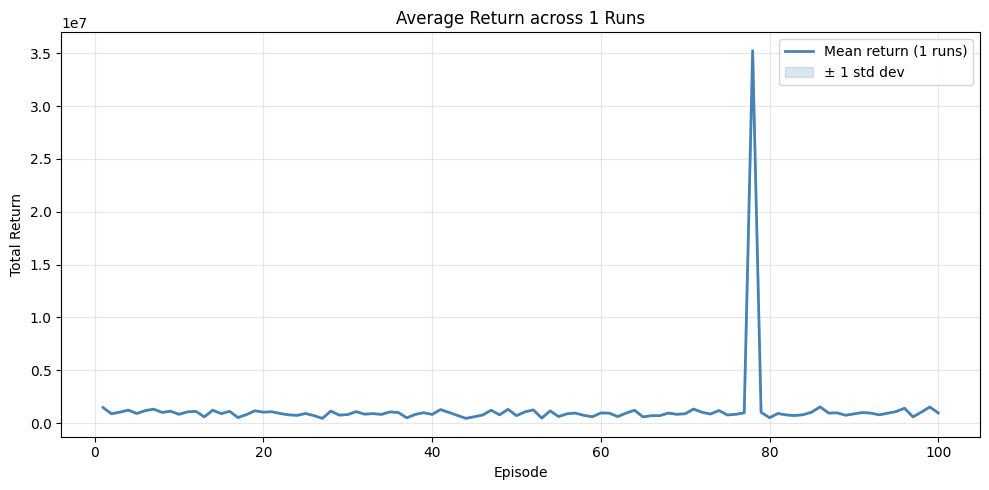

Running the learnt policy to solve the problem:**************************************************
Is initial state terminal? False
Episode ended with terminated=True
Reason: INFEASIBLE
Time taken by policy: 0:00:50.307100
Trajectory length: 77
Total return: 948391.94

Trajectory carved by the policy:---


,Action,Return from here
Step,,
1,"(2662, 'L')",948391.942
2,"(2687, 'R')",935613.875
3,"(1026, 'R')",922838.411
4,"(1050, 'L')",910067.933
5,"(1487, 'R')",897293.482
6,"(2425, 'L')",884521.897
7,"(1408, 'R')",871749.220
8,"(1176, 'R')",858983.119
9,"(2242, 'R')",846215.753



Solution in Final State: None

Objective in Final State: None

Total Return: 948391.94 over 76 steps

Reason for termination: INFEASIBLE


##########
Processing file: queens-30.mps
##########


problem Name: queens-30.mps, Num_Vars: 900, Num_Constrs: 960
The problem is a MINIMIZATION problem.

Objective Function Expression:
-1.0 C0001 + -1.0 C0002 + -1.0 C0003 + -1.0 C0004 + -1.0 C0005 + -1.0 C0006 + -1.0 C0007 + -1.0 C0008 + -1.0 C0009 + -1.0 C0010 + -1.0 C0011 + -1.0 C0012 + -1.0 C0013 + -1.0 C0014 + -1.0 C0015 + -1.0 C0016 + -1.0 C0017 + -1.0 C0018 + -1.0 C0019 + -1.0 C0020 + -1.0 C0021 + -1.0 C0022 + -1.0 C0023 + -1.0 C0024 + -1.0 C0025 + -1.0 C0026 + -1.0 C0027 + -1.0 C0028 + -1.0 C0029 + -1.0 C0030 + -1.0 C0031 + -1.0 C0032 + -1.0 C0033 + -1.0 C0034 + -1.0 C0035 + -1.0 C0036 + -1.0 C0037 + -1.0 C0038 + -1.0 C0039 + -1.0 C0040 + -1.0 C0041 + -1.0 C0042 + -1.0 C0043 + -1.0 C0044 + -1.0 C0045 + -1.0 C0046 + -1.0 C0047 + -1.0 C0048 + -1.0 C0049 + -1.0 C0050 + -1.0 C0051 + -1.0 C0052

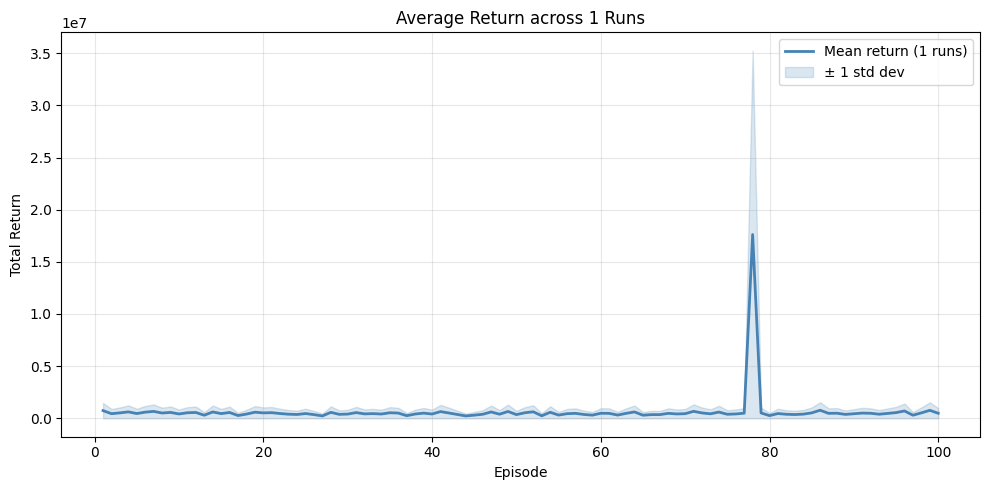

Running the learnt policy to solve the problem:**************************************************
Is initial state terminal? False
Episode ended with terminated=True
Reason: INFEASIBLE
Time taken by policy: 0:00:06.454959
Trajectory length: 73
Total return: -8845.95

Trajectory carved by the policy:---


,Action,Return from here
Step,,
1,"(3, 'L')",-8845.952
2,"(688, 'R')",-8845.951
3,"(487, 'R')",-8845.908
4,"(72, 'L')",-8846.861
5,"(759, 'L')",-8848.667
6,"(200, 'R')",-8850.477
7,"(396, 'L')",-8852.292
8,"(112, 'R')",-8855.009
9,"(822, 'L')",-8857.691



Solution in Final State: None

Objective in Final State: None

Total Return: -8845.95 over 72 steps

Reason for termination: INFEASIBLE


##########
Processing file: ramos3.mps
##########


problem Name: ramos3.mps, Num_Vars: 2187, Num_Constrs: 2187
The problem is a MINIMIZATION problem.

Objective Function Expression:
x10 + x11 + x12 + x13 + x14 + x15 + x16 + x17 + x18 + x19 + x20 + x21 + x22 + x23 + x24 + x25 + x26 + x27 + x28 + x29 + x30 + x31 + x32 + x33 + x34 + x35 + x36 + x37 + x38 + x39 + x40 + x41 + x42 + x43 + x44 + x45 + x46 + x47 + x48 + x49 + x50 + x51 + x52 + x53 + x54 + x55 + x56 + x57 + x58 + x59 + x60 + x61 + x62 + x63 + x64 + x65 + x66 + x67 + x68 + x69 + x70 + x71 + x72 + x73 + x74 + x75 + x76 + x77 + x78 + x79 + x80 + x81 + x82 + x83 + x84 + x85 + x86 + x87 + x88 + x89 + x90 + x91 + x92 + x93 + x94 + x95 + x96 + x97 + x98 + x99 + x1 + x2 + x3 + x4 + x5 + x6 + x7 + x8 + x9 + x1000 + x1001 + x1002 + x1003 + x1004 + x1005 + x1006 + x1007 + x1008 + x1009 + x1010 + x1011

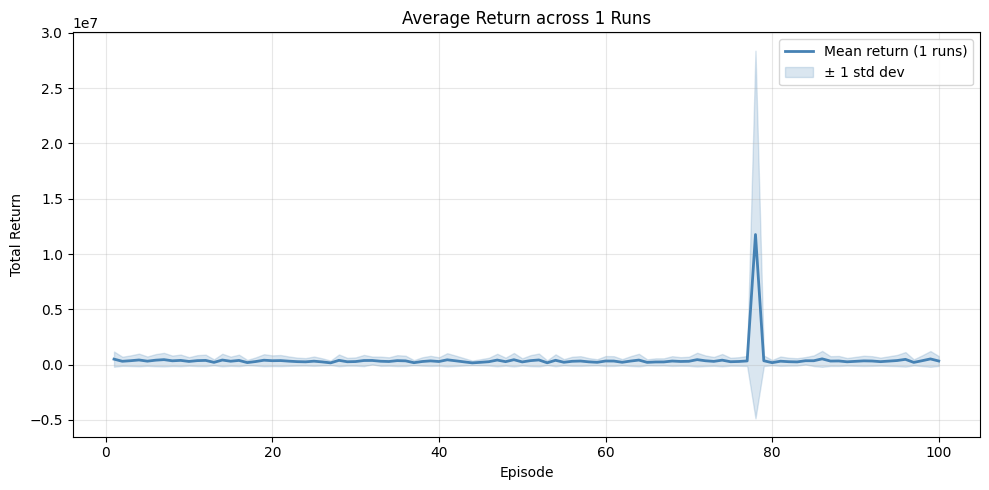

Running the learnt policy to solve the problem:**************************************************
Is initial state terminal? False
Episode ended with terminated=True
Reason: FEASIBLE (Desirable)
Time taken by policy: 0:05:28.330308
Trajectory length: 503
Total return: 37823.02

Trajectory carved by the policy:---


,Action,Return from here
Step,,
1,"(654, 'R')",37823.021
2,"(1662, 'R')",37823.021
3,"(1070, 'L')",37823.021
4,"(1552, 'R')",37823.021
5,"(1032, 'L')",37823.048
6,"(540, 'L')",37822.632
7,"(1749, 'L')",37822.215
8,"(1784, 'L')",37821.798
9,"(1272, 'R')",37821.382



Solution in Final State: [0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 1.0

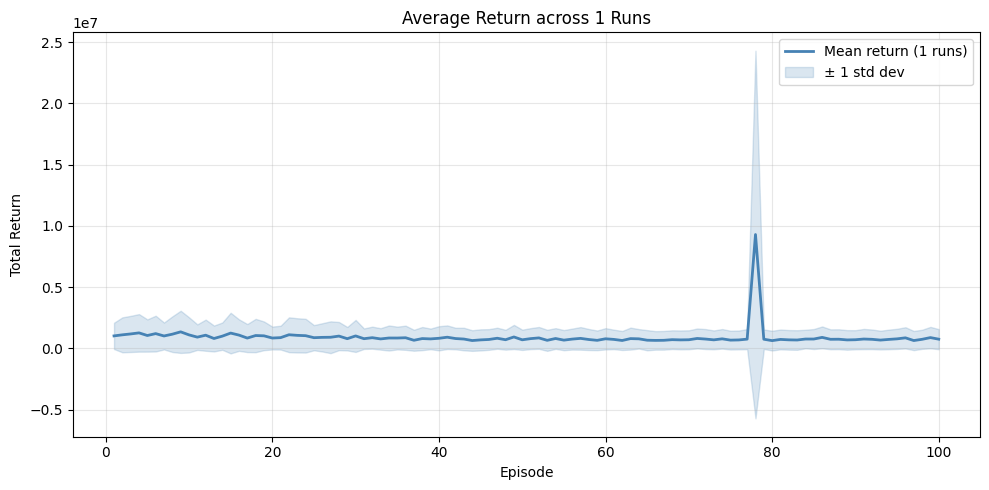

Running the learnt policy to solve the problem:**************************************************
Is initial state terminal? False
Episode ended with terminated=True
Reason: FEASIBLE (Desirable)
Time taken by policy: 0:00:12.428643
Trajectory length: 18
Total return: 1926191.33

Trajectory carved by the policy:---


,Action,Return from here
Step,,
1,"(1599, 'R')",1926191.333
2,"(340, 'R')",1883169.333
3,"(1722, 'R')",1828459.500
4,"(1934, 'R')",1754483.333
5,"(993, 'L')",1661679.333
6,"(1369, 'L')",1568658.333
7,"(1862, 'L')",1475537.333
8,"(1584, 'R')",1382296.500
9,"(372, 'R')",1258118.500



Solution in Final State: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0

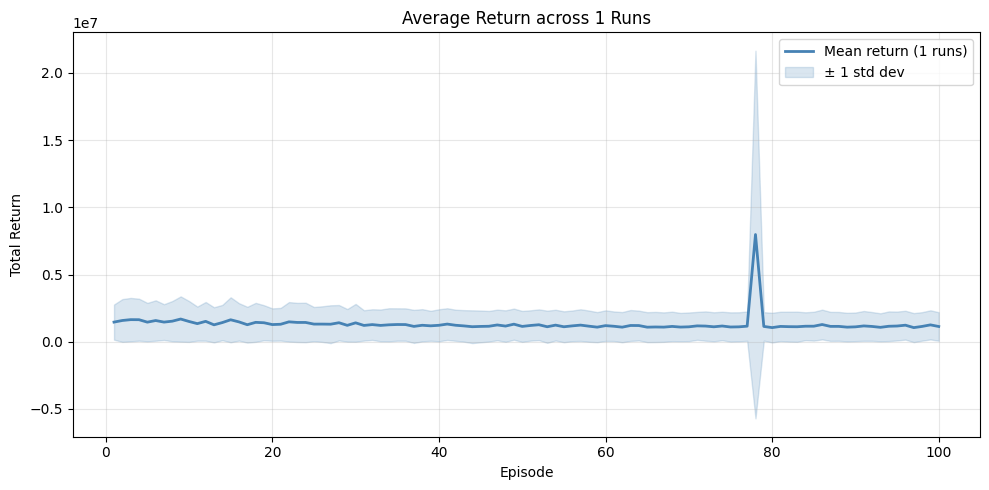

Running the learnt policy to solve the problem:**************************************************
Is initial state terminal? False
Episode ended with terminated=True
Reason: FEASIBLE (Desirable)
Time taken by policy: 0:00:25.721209
Trajectory length: 179
Total return: 2663295.83

Trajectory carved by the policy:---


,Action,Return from here
Step,,
1,"(517, 'R')",2663295.833
2,"(471, 'R')",2662821.500
3,"(1982, 'R')",2661853.833
4,"(1593, 'L')",2660392.833
5,"(1832, 'R')",2658901.667
6,"(1559, 'L')",2656938.000
7,"(1403, 'R')",2654943.833
8,"(1089, 'R')",2652564.833
9,"(1772, 'R')",2649783.333



Solution in Final State: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0

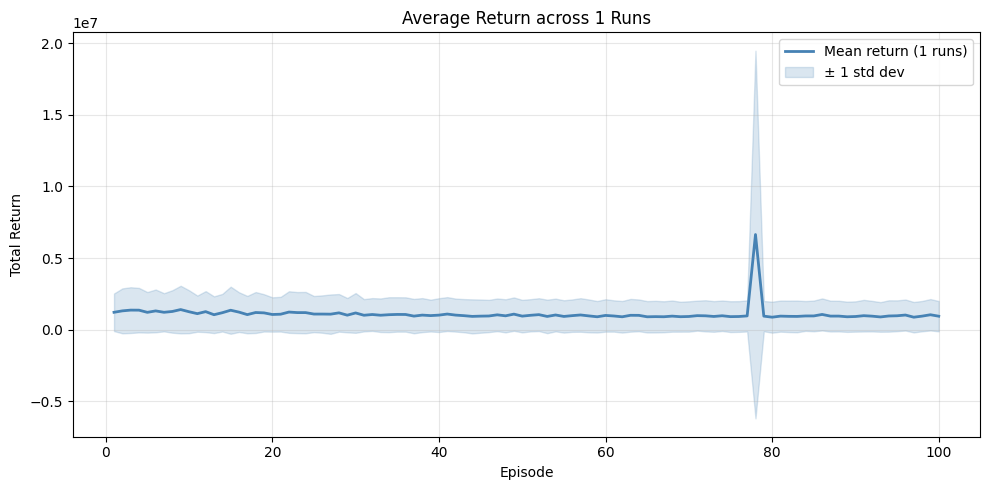

Running the learnt policy to solve the problem:**************************************************
Is initial state terminal? False
Episode ended with terminated=True
Reason: INFEASIBLE
Time taken by policy: 0:00:05.001901
Trajectory length: 60
Total return: -8888.33

Trajectory carved by the policy:---


,Action,Return from here
Step,,
1,"(31, 'L')",-8888.333
2,"(794, 'R')",-8907.500
3,"(1006, 'L')",-8926.667
4,"(943, 'L')",-8945.833
5,"(565, 'R')",-8965.000
6,"(762, 'L')",-8984.167
7,"(878, 'L')",-9003.333
8,"(880, 'L')",-9022.500
9,"(541, 'R')",-9041.667



Solution in Final State: None

Objective in Final State: None

Total Return: -8888.33 over 59 steps

Reason for termination: INFEASIBLE


##########
Processing file: v150d30-2hopcds.mps
##########


problem Name: v150d30-2hopcds.mps, Num_Vars: 150, Num_Constrs: 7822
The problem is a MINIMIZATION problem.

Objective Function Expression:
C0 + C1 + C2 + C3 + C4 + C5 + C6 + C7 + C8 + C9 + C10 + C11 + C12 + C13 + C14 + C15 + C16 + C17 + C18 + C19 + C20 + C21 + C22 + C23 + C24 + C25 + C26 + C27 + C28 + C29 + C30 + C31 + C32 + C33 + C34 + C35 + C36 + C37 + C38 + C39 + C40 + C41 + C42 + C43 + C44 + C45 + C46 + C47 + C48 + C49 + C50 + C51 + C52 + C53 + C54 + C55 + C56 + C57 + C58 + C59 + C60 + C61 + C62 + C63 + C64 + C65 + C66 + C67 + C68 + C69 + C70 + C71 + C72 + C73 + C74 + C75 + C76 + C77 + C78 + C79 + C80 + C81 + C82 + C83 + C84 + C85 + C86 + C87 + C88 + C89 + C90 + C91 + C92 + C93 + C94 + C95 + C96 + C97 + C98 + C99 + C100 + C101 + C102 + C103 + C104 + C105 + C106 + C107 + C108 + C109 + C

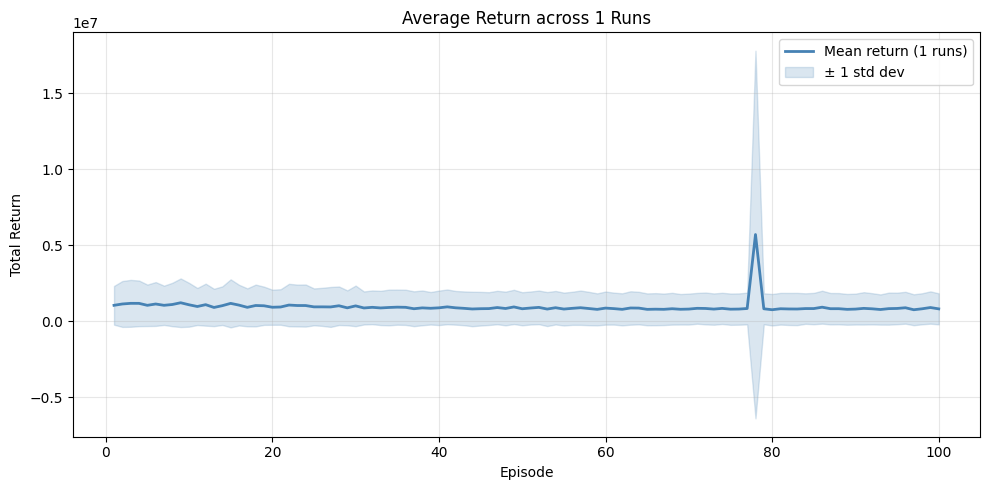

Running the learnt policy to solve the problem:**************************************************
Is initial state terminal? False
Episode ended with terminated=True
Reason: FEASIBLE (Desirable)
Time taken by policy: 0:00:03.489828
Trajectory length: 94
Total return: 154439.39

Trajectory carved by the policy:---


,Action,Return from here
Step,,
1,"(104, 'L')",154439.391
2,"(83, 'L')",153556.514
3,"(70, 'R')",152668.582
4,"(129, 'R')",151727.136
5,"(71, 'L')",150767.643
6,"(123, 'L')",149797.661
7,"(29, 'R')",148825.495
8,"(64, 'R')",147800.206
9,"(136, 'L')",146757.381



Solution in Final State: [0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 0.0, 1.0, 1.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 1.0, 1.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 1.0, 1.0, 0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 1.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0]

Objective in Final State: 61.0

Total Return: 154439.39 over 93 steps

Reason for termination: FEASIBLE (Desirable)
                    Num_Constrs Num_Vars RL_Obj     policy_time  \
circ10-3.mps              42620     270

In [60]:
# ═══════════════════════════════════════════════════════════════════════
# 6.  ENTRY POINT
# ═══════════════════════════════════════════════════════════════════════
import openpyxl
if __name__ == "__main__":
    folder_path = r"C:\Users\KISHAN\Downloads\hard_instances"
    mps_files = [f for f in os.listdir(folder_path) if f.endswith('.mps') or f.endswith('.mps.gz')]
    #mps_files = [f for f in os.listdir(folder_path) if f.startswith('2club')]
    gp_env = gp.Env(empty=True)
    gp_env.setParam("OutputFlag", 0)
    gp_env.start()
    #prob = r"C:\Users\KISHAN\Downloads\2club200v15p5scn.mps\2club200v15p5scn.mps"
    #prob = r"C:\Users\KISHAN\Downloads\v150d30-2hopcds.mps\v150d30-2hopcds.mps"
    #prob = r"C:\Users\KISHAN\Downloads\p0201.mps\p0201.mps"
    #prob = r"C:\Users\KISHAN\Downloads\stein9inf.mps\stein9inf.mps"
    results = {}
    for file_name in mps_files:
      #try: 
          file_path = os.path.join(folder_path, file_name)
          prob = file_path
          filename  = os.path.basename(file_path)         # "2club200v15p5scn.mps"
          name_only = os.path.splitext(filename)[0]  # "2club200v15p5scn"
          print(f"\n\n{'#'*10}\nProcessing file: {file_name}\n{'#'*10}")
          results[file_name] = {}
          #gmodel = load_model(prob)
          gmodel = gp.read(file_path, gp_env)
          
          
          A_scaled, b_scaled, le_mask, ge_mask, eq_mask = extract_sparse_model_matrices(gmodel)
          N = gmodel.NumIntVars
          M = gmodel.NumConstrs
          results[file_name]['Num_Vars'] = N
          results[file_name]['Num_Constrs'] = M
          sense = gmodel.ModelSense
          #n_steps = N + 50
          print(f"\n\nproblem Name: {file_name}, Num_Vars: {N}, Num_Constrs: {M}")
          if sense == gp.GRB.MINIMIZE:  # or sense == 1
            print("The problem is a MINIMIZATION problem.")
          elif sense == gp.GRB.MAXIMIZE:  # or sense == -1
            print("The problem is a MAXIMIZATION problem.")
          print("\nObjective Function Expression:")
          print(gmodel.getObjective())
          gmodel = gmodel.relax()  # Relax the model to get fractional solutions
          time1 = time.perf_counter()
          tc, obj_val, x_val = solve_bip_gurobi(gmodel, vec=None, relax=False)
          time2 = time.perf_counter()
          print(f"Time taken by solver:", datetime.timedelta(seconds=time2-time1))
          #print("Number of binary variables:", N)
          #print("Number of constraints:", M)
          print("Solution of the Relaxation:------------")
          print(f"\nX: {np.round(x_val,2)}, Obj = {np.round(obj_val,2)}")
          env = MyMDPEnv(N,gmodel,episodes,A_scaled, b_scaled, le_mask, ge_mask, eq_mask) 
          state, _ = env.reset()
          print(f"\nInitial state: {state}")            
          print(f"\nIs terminal: {env.is_terminal(state)}")
          time3 = time.perf_counter()
          for run in range(N_runs):
            print(f"\n{'='*50}")
            print(f"RUN {run+1}/{N_runs}")
            print(f"{'='*50}")
            actor, critic, episode_returns = actor_critic_nn(
                      env        = env,
                      is_terminal= env.is_terminal,         # <<< CHANGE >>> your function
                      gamma      = 1.0,                 # <<< CHANGE >>> no discounting for episodic tasks
                      alpha_w    = 1e-3,
                      alpha_theta= 1e-4,
                      tau        = 0.005,
                      hidden_dim = 128,                 # <<< CHANGE >>> increase for complex problems
                      n_episodes = episodes,
                      device= device,
                      entropy_coeff_start = 0.9,    # <<< high exploration at start
                      entropy_coeff_end = 0.01,
                      epsilon = 0.2
                  )
              
                

            '''actor, critic, episode_returns = actor_critic_with_backtrack(
                env        = env,
                gamma      = 1.0,
                alpha_w    = 1e-3,
                alpha_theta= 1e-4,
                tau        = 0.005,
                hidden_dim = 128,
                n_episodes = episodes,
                max_backtracks = 5,
                device= device,
                entropy_coeff_start = 0.9,
                entropy_coeff_end = 0.01
            )'''
            all_returns.append(episode_returns)
          time4 = time.perf_counter()
          print("\nTraining complete.")
          print(f"Total time across runs:", datetime.timedelta(seconds=time4-time3))
          mean_returns = np.mean(all_returns, axis=0)   # shape: (m_episodes,) — avg of ep_i across N runs
          std_returns  = np.std(all_returns,  axis=0)   # shape: (m_episodes,) — std  of ep_i across N runs
          plot_averaged_returns(all_returns, N_runs)
          print("Running the learnt policy to solve the problem:**************************************************")
          time5 = time.perf_counter()
          trajectory, total_return, obj_final, x_final, reason = run_policy_nn(env, actor, device=device, hours=0.1)   # <<< CHANGE >>>
          time6 = time.perf_counter()
          print(f"Time taken by policy:", datetime.timedelta(seconds=time6-time5))
          print(f"Trajectory length: {len(trajectory)}")
          print(f"Total return: {total_return:.2f}")

          # Inspect policy at any state — e.g. the first state in the trajectory
          state0, _, _ = trajectory[0]
          valid = env.compute_feasible_actions(state0)
          print("\nTrajectory carved by the policy:---")
          print_trajectory(trajectory, env)
          print(f"\nSolution in Final State: {x_final}")
          print(f"\nObjective in Final State: {obj_final}")
          print(f"\nTotal Return: {total_return:.2f} over {len(trajectory)-1} steps")
          print(f"\nReason for termination: {reason}")
          #plot_policy_at_step_nn(actor, trajectory, step=0, env=env, device=device) 
          results[file_name]['RL_Obj'] = obj_final      
          results[file_name]['train_time'] = datetime.timedelta(seconds=time4-time3)
          results[file_name]['policy_time'] = datetime.timedelta(seconds=time6-time5)
          results[file_name]['tot_time'] = results[file_name]['train_time'] + results[file_name]['policy_time']
    '''except RuntimeError as e:
                      # Catch the specific shape mismatch error
                  if "shapes cannot be multiplied" in str(e):
                      
                      # This keyword tells Python to skip the rest of this try block
                      # and move directly to instance_id + 1
                      continue 
                      
                  else:
                      # If it's a different RuntimeError (like Out of Memory), 
                      # let it crash so you know about it
                      raise e '''
    df=pd.DataFrame(results)

    # 2. Transpose so Model names become Rows for now, metrics become Columns
    df = df.T
    columns_hierarchy = [
    ("Num_Vars", ""),
    ("Num_Constrs",""),
    ("RL_Heuristic", "RL_Obj"),
    ("RL_Heuristic", "train_time"),
    ("RL_Heuristic", "policy_time"),
    ("RL_Heuristic", "tot_time"),]
    '''df.columns = pd.MultiIndex.from_tuples(
    columns_hierarchy, 
    names=["Solver", "Mode", "Metrics"])
    df.columns = pd.MultiIndex.from_tuples(columns_hierarchy)'''

  # 3. Sort columns so the "Performance" categories group together completely
    df = df.sort_index(axis=1)
    #df.to_csv("gurobi_results.csv", index= True)
    output_file = "Feas_loss_actor-critic.xlsx"

    with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
        # merge_cells=True is the magic switch here. 
        # It tells Pandas to physically merge cells across columns instead of repeating text.
        df.to_excel(writer, sheet_name="Master Summary", merge_cells=True, index=True)
        print(df)


NameError: name 'df' is not defined